# Sales Data: Exploratory Data Analysis
US retail orders, 2019-2020 (5,901 rows). Cleaning comes first, then one section per column, with a **Finding** line under each result. The conclusion is at the bottom.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(r'C:\Users\adikh\Downloads\sales_data (1).csv',encoding='unicode_escape')

In [5]:
df.shape

(5901, 23)

In [6]:
df.head()

,Row ID+O6G3A1:R6,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,ind1,ind2
0,4918,CA-2019-160304,1/1/2019,1/7/2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",73.94,1,28.2668,NaN,Online,NaN,NaN
1,4919,CA-2019-160304,1/2/2019,1/7/2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",173.94,3,38.2668,NaN,Online,NaN,NaN
2,4920,CA-2019-160304,1/2/2019,1/7/2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Technology,Phones,GE 30522EE2,231.98,2,67.2742,NaN,Cards,NaN,NaN
3,3074,CA-2019-125206,1/3/2019,1/5/2019,First Class,LR-16915,Lena Radford,Consumer,United States,Los Angeles,...,Office Supplies,Storage,Recycled Steel Personal File for Hanging File ...,114.46,2,28.6150,NaN,Online,NaN,NaN
4,8604,US-2019-116365,1/3/2019,1/8/2019,Standard Class,CA-12310,Christine Abelman,Corporate,United States,San Antonio,...,Technology,Accessories,ImationÂ Clip USBÂ flash driveÂ - 8 GB,30.08,2,-5.2640,NaN,Online,NaN,NaN


In [7]:
df.tail()

,Row ID+O6G3A1:R6,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,ind1,ind2
5896,907,CA-2020-143259,12/30/2020,1/3/2021,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Fully Ass...",213.136,4,12.1176,NaN,COD,NaN,NaN
5897,1297,CA-2020-115427,12/30/2020,1/3/2021,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,Office Supplies,Binders,"Cardinal Slant-D Ring Binder, Heavy Gauge Vinyl",295.904,2,4.5188,1.0,Online,NaN,NaN
5898,5092,CA-2020-156720,12/30/2020,1/3/2021,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,Office Supplies,Fasteners,Bagged Rubber Bands,388.024,3,-0.6048,NaN,Online,NaN,NaN
5899,909,CA-2020-143259,12/30/2020,1/3/2021,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,462.776,3,19.7910,NaN,COD,NaN,NaN
5900,5093,CA-2020-151450,12/31/2020,1/4/2021,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,Office Supplies,Fasteners,Bagged Rubber Bands,2975.510,3,-0.6048,NaN,COD,NaN,NaN


In [8]:
df.drop(['ind1','ind2'],axis = 1,inplace = True)

In [9]:
df['Returns'].value_counts(dropna=False)

Returns
NaN    5614
1.0     287
Name: count, dtype: int64

In [10]:
df['Returns'] = df['Returns'].fillna(0).astype(int)

In [11]:
df['Return Status'] = df['Returns'].map({0: 'Not Returned', 1: 'Returned'})

*0 stands for not returned and 1 stands for returned*

In [ ]:
df.head(10)

In [12]:
df['Row ID+O6G3A1:R6'].duplicated().sum()

np.int64(1)

In [13]:
df[df['Row ID+O6G3A1:R6'].duplicated(keep=False)]

,Row ID+O6G3A1:R6,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,Return Status
0,4918,CA-2019-160304,1/1/2019,1/7/2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,FUR-BO-10004709,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",73.940,1,28.2668,0,Online,Not Returned
4773,4918,CA-2020-163125,10/9/2020,10/11/2020,Second Class,MB-17305,Maria Bertelson,Consumer,United States,League City,...,FUR-CH-10001802,Furniture,Chairs,Hon Every-Day Chair Series Swivel Task Chairs,272.058,3,-32.6646,0,COD,Not Returned


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5901 entries, 0 to 5900
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Row ID+O6G3A1:R6  5901 non-null   int64  
 1   Order ID          5901 non-null   str    
 2   Order Date        5901 non-null   str    
 3   Ship Date         5901 non-null   str    
 4   Ship Mode         5901 non-null   str    
 5   Customer ID       5901 non-null   str    
 6   Customer Name     5901 non-null   str    
 7   Segment           5901 non-null   str    
 8   Country           5901 non-null   str    
 9   City              5901 non-null   str    
 10  State             5901 non-null   str    
 11  Region            5901 non-null   str    
 12  Product ID        5901 non-null   str    
 13  Category          5901 non-null   str    
 14  Sub-Category      5901 non-null   str    
 15  Product Name      5901 non-null   str    
 16  Sales             5901 non-null   float64
 17  Quanti

In [15]:
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%m/%d/%Y')
df.dtypes[['Order Date', 'Ship Date']]     

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [16]:
df['Customer Name'].duplicated().sum()

df['Customer Name'].nunique()

773

*773 unique customers generate 5,128 repeat order rows (on top of their first order each), out of 5,901 total rows.*

In [17]:
df[df['Returns'] == 1]['Order ID'].nunique()

104

*so out of those 773 customers 104 have returns even atleast 1 or more*

In [18]:
# Order-level return rate (a returned order counts once, however many rows it has)
returned_orders = df[df['Returns'] == 1]['Order ID'].nunique()
all_orders = df['Order ID'].nunique()
print("returned orders:", returned_orders, "| total orders:", all_orders)
print("order-level return rate:", round(returned_orders / all_orders * 100, 1), "%")
print("row-level return rate:", round(df['Returns'].mean() * 100, 1), "%")

returned orders: 104 | total orders: 3003
order-level return rate: 3.5 %
row-level return rate: 4.9 %


**Finding:** Returns are 4.9% of rows (287 rows) but only 3.5% of orders (104 out of 3,003), because a returned order marks every row in it. Use the order-level number for dashboards.

In [19]:
df.isnull().sum()

Row ID+O6G3A1:R6    0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Profit              0
Returns             0
Payment Mode        0
Return Status       0
dtype: int64

In [20]:
df.describe()

,Row ID+O6G3A1:R6,Order Date,Ship Date,Sales,Quantity,Profit,Returns
count,5901.000000,5901,5901,5901.000000,5901.000000,5901.000000,5901.000000
mean,5022.422471,2020-02-29 01:53:57.620742,2020-03-04 00:08:47.097102,265.345589,3.781901,29.700408,0.048636
min,1.000000,2019-01-01 00:00:00,2019-01-05 00:00:00,0.836000,1.000000,-6599.978000,0.000000
25%,2486.000000,2019-09-11 00:00:00,2019-09-15 00:00:00,71.976000,2.000000,1.795500,0.000000
50%,5091.000000,2020-03-16 00:00:00,2020-03-19 00:00:00,128.648000,3.000000,8.502500,0.000000
75%,7456.000000,2020-09-14 00:00:00,2020-09-16 00:00:00,265.170000,5.000000,28.615000,0.000000
max,9994.000000,2020-12-31 00:00:00,2021-01-05 00:00:00,9099.930000,14.000000,8399.976000,1.000000
std,2877.977184,NaN,NaN,474.260645,2.212917,259.589138,0.215124


## Exploratory Data Analysis

### Ship Mode

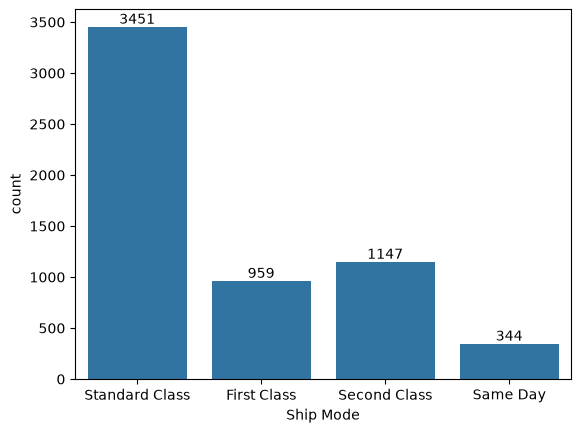

In [21]:
ax = sns.countplot(data = df,x = 'Ship Mode')

for container in ax.containers:
    ax.bar_label(container)

*Standard Class is the one leading here as its frequency is way more than the others*

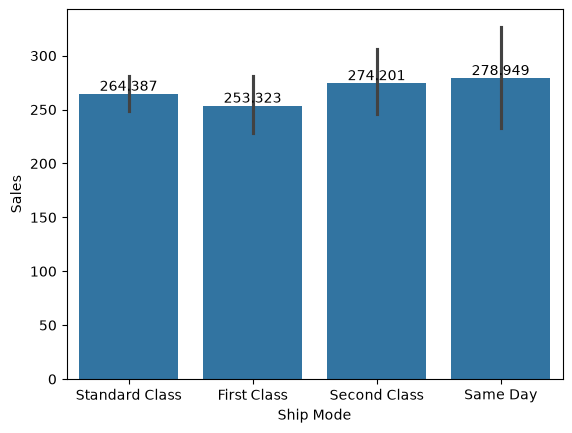

In [22]:
ax = sns.barplot(data = df,x = 'Ship Mode',y = 'Sales')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Ship Mode', ylabel='Sales'>

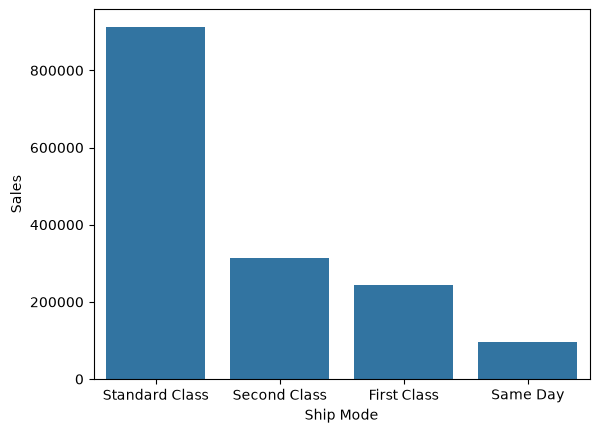

In [23]:
Salesbyshipmode = df.groupby(['Ship Mode'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = Salesbyshipmode,x = 'Ship Mode',y = 'Sales')

In [24]:
df.groupby('Ship Mode')['Sales'].agg(['count','mean','median'])

,count,mean,median
Ship Mode,,,
First Class,959,253.322961,131.86
Same Day,344,278.949131,130.52
Second Class,1147,274.200579,129.85
Standard Class,3451,264.387435,127.88


In [25]:
df.groupby('Ship Mode')[['Sales','Profit']].sum().assign(margin=lambda d: d.Profit/d.Sales*100)

,Sales,Profit,margin
Ship Mode,,,
First Class,242936.7194,29749.8665,12.245932
Same Day,95958.5010,8808.8243,9.179827
Second Class,314508.0640,36936.0265,11.744063
Standard Class,912401.0388,99767.3886,10.934598


In [26]:
df.groupby('Ship Mode')['Returns'].mean()*100

Ship Mode
First Class       6.882169
Same Day          2.906977
Second Class      4.969486
Standard Class    4.462475
Name: Returns, dtype: float64

**Finding:** Standard Class brings 58% of sales (912k). The average sale is about the same in every mode (~$265, median ~$128). Margin ranges only from 9.2% (Same Day) to 12.2% (First Class). First Class has the highest return rate (6.9%), Same Day the lowest (2.9%). Ship Mode doesn't change much.

### Segment

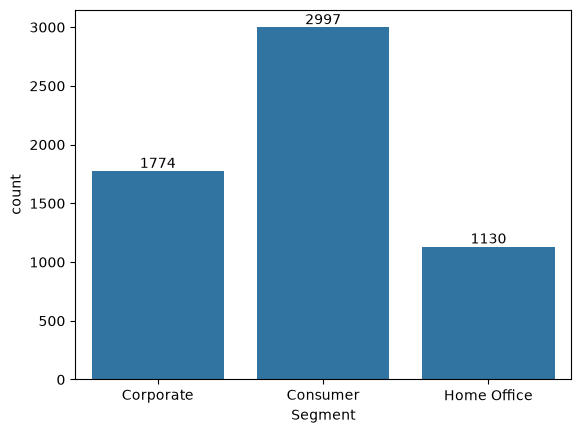

In [27]:
ax = sns.countplot(data = df,x = 'Segment')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Segment', ylabel='Sales'>

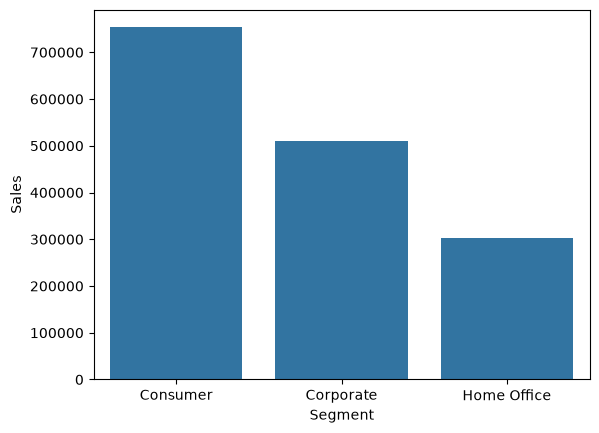

In [28]:
totalsalesbysegment = df.groupby(['Segment'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = totalsalesbysegment,x = 'Segment',y = 'Sales')

In [29]:
g = df.groupby('Segment').agg(
    orders=('Sales', 'count'),
    avg_sale=('Sales', 'mean'),
    median_sale=('Sales', 'median'),
    profit=('Profit', 'sum'),
    return_rate=('Returns', 'mean')
)
g['margin'] = df.groupby('Segment')['Profit'].sum() / df.groupby('Segment')['Sales'].sum() * 100
g['return_rate'] *= 100
print(g)

             orders    avg_sale  median_sale      profit  return_rate  \
Segment                                                                 
Consumer       2997  251.251962      129.424  81338.5875     4.671338   
Corporate      1774  287.341108      129.990  57805.7991     5.580609   
Home Office    1130  268.193865      125.616  36117.7193     4.247788   

                margin  
Segment                 
Consumer     10.801907  
Corporate    11.340182  
Home Office  11.917716  


**Finding:** Consumer is the biggest segment (753k sales, 48%, and the most profit at 81k). Corporate has the highest average sale (287) and the highest return rate (5.6%). Home Office has the best margin (11.9%). All three are within about 1 point of margin of each other.

### Ship Mode by Segment

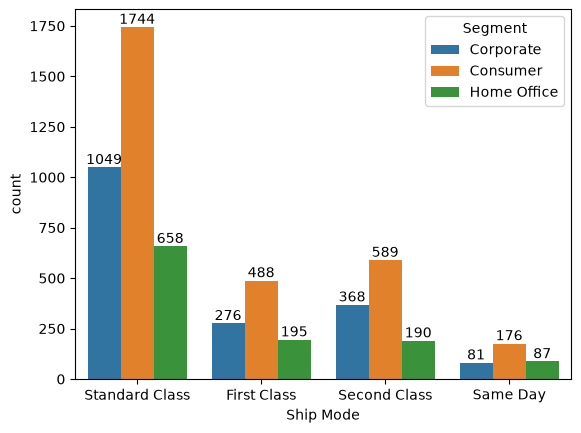

In [30]:
ax = sns.countplot(data = df,x = 'Ship Mode',hue = 'Segment')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Ship Mode', ylabel='Sales'>

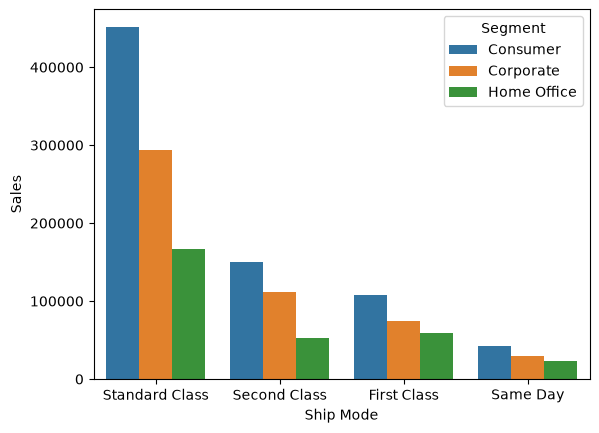

In [31]:
salesbyshipping = df.groupby(['Ship Mode','Segment'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = salesbyshipping,x = 'Ship Mode',y = 'Sales',hue = 'Segment')

In [32]:
pd.crosstab(df['Segment'], df['Ship Mode'], normalize='index').round(3) * 100

Ship Mode,First Class,Same Day,Second Class,Standard Class
Segment,,,,
Consumer,16.3,5.9,19.7,58.2
Corporate,15.6,4.6,20.7,59.1
Home Office,17.3,7.7,16.8,58.2


<Axes: ylabel='Segment'>

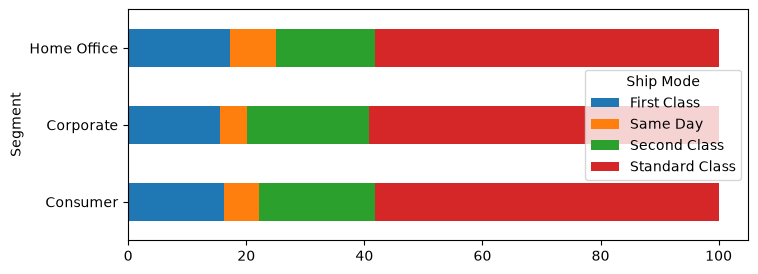

In [33]:
pd.crosstab(df['Segment'], df['Ship Mode'], normalize='index').mul(100).plot(kind='barh', stacked=True, figsize=(8,3))

**Finding:** Every segment ships about 58% Standard, 16-17% First Class, 17-21% Second Class and 5-8% Same Day. No segment behaves differently.

### Region

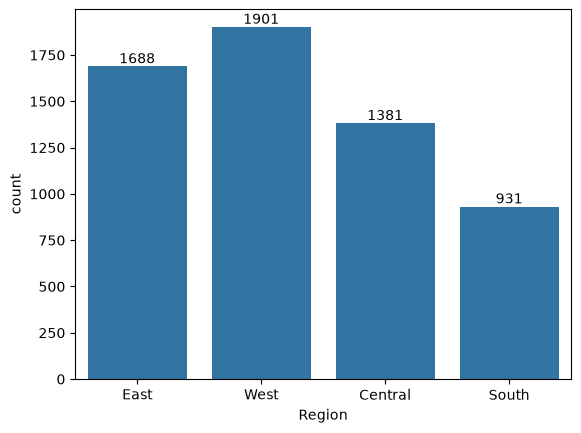

In [34]:
ax = sns.countplot(data = df,x = 'Region')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Region', ylabel='Sales'>

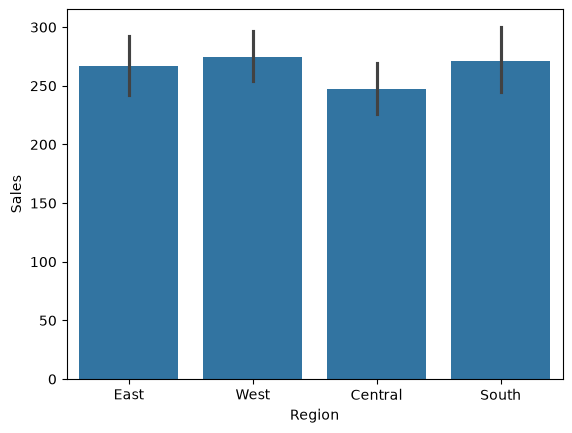

In [35]:
sns.barplot(data = df, x = 'Region',y = 'Sales')

<Axes: xlabel='Region', ylabel='Sales'>

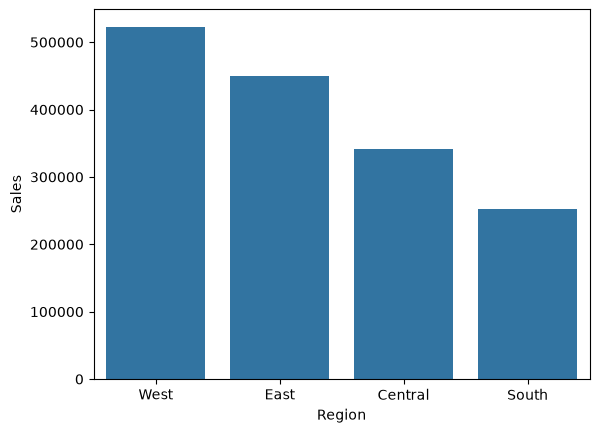

In [36]:
sales_regionwise = df.groupby(['Region'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = sales_regionwise,x = 'Region',y = 'Sales')

In [37]:
g = df.groupby('Region').agg(
    orders=('Sales', 'count'),
    sales=('Sales', 'sum'),
    avg_sale=('Sales', 'mean'),
    median_sale=('Sales', 'median'),
    profit=('Profit', 'sum'),
    return_rate=('Returns', 'mean')
)
g['margin'] = g['profit'] / g['sales'] * 100
g['return_rate'] *= 100
print(g.round(1))

         orders     sales  avg_sale  median_sale   profit  return_rate  margin
Region                                                                        
Central    1381  341007.5     246.9        123.9  27450.0          2.2     8.0
East       1688  450234.7     266.7        129.8  53400.4          2.8    11.9
South       931  252121.1     270.8        127.6  26551.7          2.1    10.5
West       1901  522441.1     274.8        131.3  67860.0          9.9    13.0


<Axes: xlabel='Region', ylabel='Sales'>

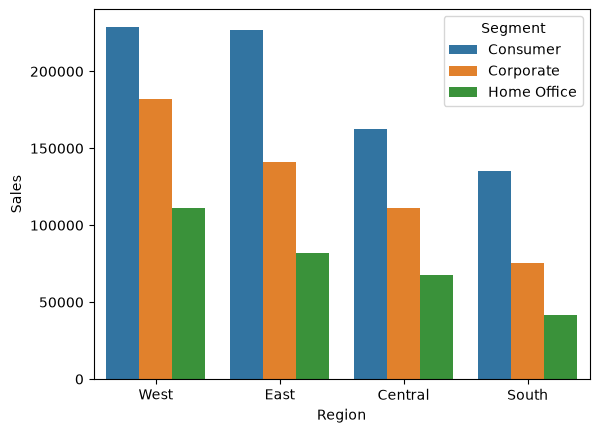

In [38]:
sales_regionwise = df.groupby(['Region','Segment'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = sales_regionwise,x = 'Region',y = 'Sales',hue = 'Segment')

<Axes: xlabel='Region', ylabel='Sales'>

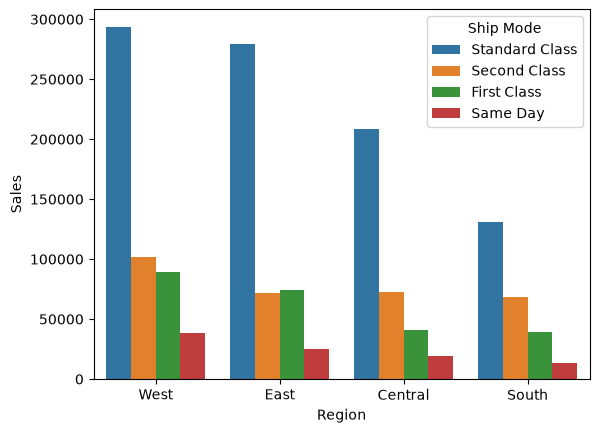

In [39]:
salesshippingbyregion = df.groupby(['Region','Ship Mode'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = salesshippingbyregion,x = 'Region',y = 'Sales',hue = 'Ship Mode')

**Finding:** West leads on sales (522k, 33%), profit (68k) and margin (13.0%). Central is weakest on margin (8.0%). Return rate is about 2-3% in Central, East and South but 9.9% in West, so West needs a closer look (below).

In [40]:
# Order-level return rate by region (a returned order counts once)
orders = df.groupby('Region')['Order ID'].nunique()
returned = df[df['Returns'] == 1].groupby('Region')['Order ID'].nunique()
print(pd.DataFrame({'orders': orders, 'returned_orders': returned, 'return_rate %': (returned / orders * 100).round(2)}))

         orders  returned_orders  return_rate %
Region                                         
Central     711               15           2.11
East        844               13           1.54
South       487                6           1.23
West        961               70           7.28


**Finding:** Counting orders instead of rows, West is 7.28% (70 of 961 orders), Central 2.11%, East 1.54% and South 1.23%. West looks lower than the row-based 9.9% because its returned orders are bigger than average (about 2.7 rows each vs about 2 rows for a normal order), but West is still clearly the outlier. The Power BI dashboard uses this order-based rate.

#### Digging into West: where do the returns come from?

In [41]:
# 2. Return counts by region
df.groupby('Region')['Returns'].agg(['sum', 'count', 'mean'])

,sum,count,mean
Region,,,
Central,31,1381,0.022448
East,48,1688,0.028436
South,20,931,0.021482
West,188,1901,0.098895


In [42]:
# 3. Inside West: by category, then by state
w = df[df['Region'] == 'West']

w.groupby('State')['Returns'].agg(['sum', 'count', 'mean']).sort_values('sum', ascending=False).head(5)

,sum,count,mean
State,,,
California,147,1189,0.123633
Washington,27,337,0.080119
Arizona,7,113,0.061947
Oregon,3,65,0.046154
Colorado,2,114,0.017544


In [43]:
# 4. Inside California: by category, sub-category, city
ca = df[df['State'] == 'California']

ca.groupby('City')['Returns'].agg(['sum', 'count', 'mean']).sort_values('sum', ascending=False).head(5)

,sum,count,mean
City,,,
Los Angeles,45,430,0.104651
San Francisco,22,304,0.072368
Brentwood,9,10,0.900000
Fairfield,9,9,1.000000
Inglewood,8,16,0.500000


In [44]:
# 5. The odd small cities, by customer
odd = df[df['City'].isin(['Brentwood', 'Fairfield', 'Inglewood'])]
odd.groupby(['City', 'Customer Name'])['Returns'].agg(['sum', 'count'])

sum  count
City      Customer Name                
Brentwood Brad Norvell         0      1
          Deborah Brumfield    2      2
          Rick Wilson          7      7
Fairfield Alan Dominguez       0      2
          Cari Schnelling      0      1
          Chris Cortes         0      2
          Dave Hallsten        7      7
          Erica Bern           2      2
          Kelly Lampkin        0      2
          Larry Tron           0      1
          Liz Preis            0      2
          Nat Gilpin           0      2
          Ricardo Sperren      0      1
          Roy Collins          0      1
          Sally Knutson        0      1
          Shahid Collister     0      3
          Shirley Jackson      0      2
          Susan Vittorini      0      4
          Ted Butterfield      0      1
Inglewood Barry Blumstein      0      2
          Dan Reichenbach      8      8
          Khloe Miller         0      3
          Luke Foster          0      3

In [45]:
c = df.groupby('Customer Name')['Returns'].agg(['sum', 'count', 'mean'])
(c['sum'] > 0).sum()                  # customers with any return (you got 104)
(c['mean'] == 1).sum()                # customers who returned everything
c[c['sum'] > 0].sort_values('sum', ascending=False).head(10)

,sum,count,mean
Customer Name,,,
Seth Vernon,14,25,0.560000
Stefania Perrino,8,15,0.533333
Dan Reichenbach,8,19,0.421053
Patrick Ryan,7,8,0.875000
Greg Guthrie,7,14,0.500000
Thomas Seio,7,9,0.777778
Rick Wilson,7,14,0.500000
Dave Hallsten,7,8,0.875000
Jay Kimmel,6,9,0.666667


In [46]:
# 7. Are returns flagged per row or per whole order?
df[df['Returns'] == 1]['Order ID'].nunique()
df[df['Customer Name'] == 'Seth Vernon'][['Order ID', 'Order Date', 'Sub-Category', 'Sales', 'Returns']]

,Order ID,Order Date,Sub-Category,Sales,Returns
792,CA-2019-118745,2019-06-11,Tables,902.712,0
1540,CA-2019-157511,2019-09-18,Furnishings,5.352,0
1541,CA-2019-157511,2019-09-18,Chairs,99.372,0
1542,CA-2019-157511,2019-09-18,Art,2.672,0
1992,US-2019-136581,2019-11-10,Paper,31.104,0
3901,US-2020-165358,2020-07-18,Chairs,214.744,0
3903,US-2020-165358,2020-07-18,Copiers,641.970,0
3906,US-2020-165358,2020-07-18,Supplies,113.184,0
4027,CA-2020-161200,2020-08-06,Bookcases,190.740,0
4031,CA-2020-161200,2020-08-06,Furnishings,120.400,0


**Finding:** West has 188 of the 287 returned rows. California alone has 147 (12.4% of its rows) and Washington 27 (8.0%). In California, Los Angeles has the most returns (45). The tiny cities (Brentwood, Fairfield, Inglewood) have 50-100% return rates because one customer in each (Rick Wilson, Dave Hallsten, Dan Reichenbach) returned everything they bought. The top returner overall is Seth Vernon (14 rows). Returns are flagged on the whole order, not row by row: Seth's order CA-2020-100111 has all 14 rows returned. So the West return rate comes from a few customers, not from the whole region.

#### Does shipping time affect returns?

In [47]:
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Ship Speed'] = pd.cut(df['Ship Days'], [-1, 2, 4, 8], labels=['0-2 days', '3-4 days', '5-8 days'])
print(df.groupby('Ship Speed', observed=True)['Returns'].agg(['count', 'sum', 'mean']))
print("correlation:", round(df['Ship Days'].corr(df['Returns']), 3))

            count  sum      mean
Ship Speed                      
0-2 days     1374   69  0.050218
3-4 days     2176  103  0.047335
5-8 days     2351  115  0.048915
correlation: 0.002


**Finding:** Shipping time doesn't affect returns: the return rate is 5.0% for 0-2 days, 4.7% for 3-4 days and 4.9% for 5-8 days, and the correlation is about 0.00. West stays near 10% whether delivery is fast or slow, so the West returns are not a shipping problem.

### Category

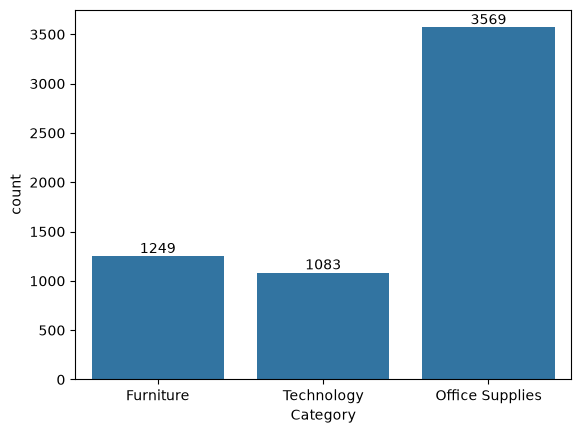

In [48]:
ax = sns.countplot(data = df,x = 'Category')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Category', ylabel='Sales'>

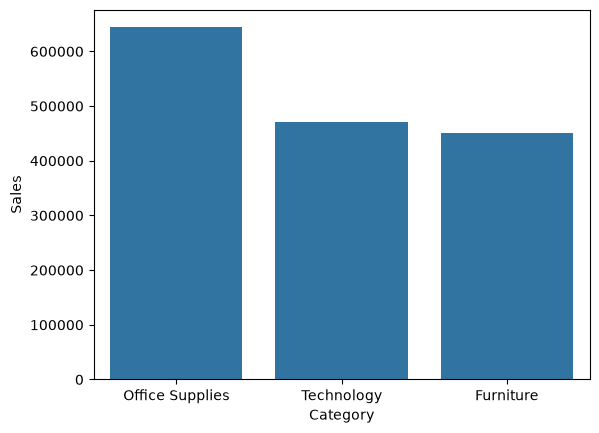

In [49]:
Salesbycategory = df.groupby(['Category'],as_index= False)['Sales'].sum().sort_values(by = 'Sales',ascending = False)

sns.barplot(data = Salesbycategory,x = 'Category',y = 'Sales')

<Axes: xlabel='Category', ylabel='Sales'>

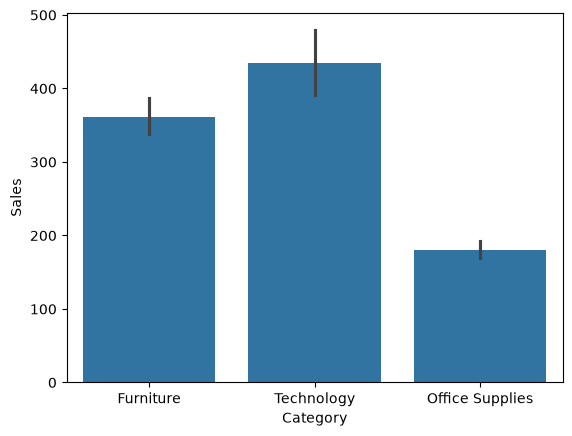

In [50]:
sns.barplot(data = df,x = 'Category',y = 'Sales')

In [51]:
cat = df.groupby('Category').agg(
    orders=('Sales', 'count'),
    sales=('Sales', 'sum'),
    avg_sale=('Sales', 'mean'),
    median_sale=('Sales', 'median'),
    profit=('Profit', 'sum'),
    return_rate=('Returns', 'mean')
)
cat['margin'] = cat['profit'] / cat['sales'] * 100
cat['return_rate'] *= 100
print(cat.round(1))

                 orders     sales  avg_sale  median_sale   profit  \
Category                                                            
Furniture          1249  451508.6     361.5        209.9  10006.6   
Office Supplies    3569  643707.7     180.4        112.0  74797.2   
Technology         1083  470588.0     434.5        188.8  90458.2   

                 return_rate  margin  
Category                              
Furniture                5.6     2.2  
Office Supplies          4.6    11.6  
Technology               4.8    19.2  


**Finding:** Office Supplies has the most orders and sales (644k, 41%). Technology earns the most profit (90k) with the best margin (19.2%) from the fewest orders. Furniture is barely profitable (2.2% margin) even with 451k of sales. Return rate is about the same across categories (4.6-5.6%).

In [52]:
(df.groupby(['Region', 'Category'])[['Sales', 'Profit']].sum()
   .assign(margin=lambda d: d.Profit / d.Sales * 100)
   .round(1))

Sales   Profit  margin
Region  Category                                  
Central Furniture        105505.5  -1534.8    -1.5
        Office Supplies  150154.4   6477.6     4.3
        Technology        85347.7  22507.2    26.4
East    Furniture        117072.0   3621.5     3.1
        Office Supplies  189066.8  23248.6    12.3
        Technology       144095.9  26530.3    18.4
South   Furniture         72984.9   2562.0     3.5
        Office Supplies   99652.1  11105.0    11.1
        Technology        79484.1  12884.7    16.2
West    Furniture        155946.4   5357.9     3.4
        Office Supplies  204834.4  33966.0    16.6
        Technology       161660.3  28536.1    17.7

**Finding:** Furniture loses money in Central (-1.5%). Technology has its best margin in Central (26.4%). West is the best region for Office Supplies (16.6%).

In [53]:
fur = df[df['Category'] == 'Furniture']
s = fur.groupby('Sub-Category')[['Sales', 'Profit']].sum()
s['margin'] = s['Profit'] / s['Sales'] * 100
print(s.sort_values('margin').round(1))

                 Sales   Profit  margin
Sub-Category                           
Tables        119293.7 -11091.6    -9.3
Bookcases      57577.7   -342.9    -0.6
Chairs        181946.0  13406.7     7.4
Furnishings    92691.2   8034.4     8.7


**Finding:** Inside Furniture, Tables (-9.3%) and Bookcases (-0.6%) lose money, pulling the whole category down. Chairs (7.4%) and Furnishings (8.7%) are fine.

### Sub-Category

In [54]:
sub = df.groupby('Sub-Category')[['Sales', 'Profit']].sum()
sub['margin'] = sub['Profit'] / sub['Sales'] * 100
print(sub.sort_values('margin').round(1))

                 Sales   Profit  margin
Sub-Category                           
Tables        119293.7 -11091.6    -9.3
Supplies       36721.0  -1654.3    -4.5
Bookcases      57577.7   -342.9    -0.6
Machines       91987.6     38.1     0.0
Fasteners      15205.2    598.4     3.9
Art            50763.0   3635.9     7.2
Chairs        181946.0  13406.7     7.4
Furnishings    92691.2   8034.4     8.7
Storage       150341.3  13607.1     9.1
Binders       174978.4  17885.4    10.2
Phones        196563.5  22308.9    11.3
Labels         19397.5   2937.2    15.1
Appliances     80305.2  13166.6    16.4
Accessories   122301.1  25336.6    20.7
Envelopes      16542.5   3508.5    21.2
Paper          99453.6  21112.4    21.2
Copiers        59735.8  42774.6    71.6


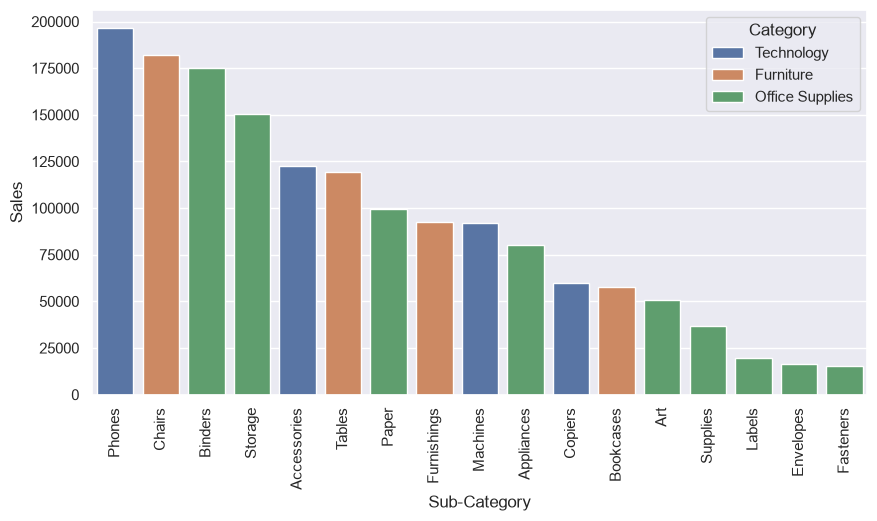

In [55]:
Salesbysubcategory = df.groupby(
    ['Sub-Category', 'Category'], as_index=False
)['Sales'].sum().sort_values(by='Sales', ascending=False)

sns.set(rc={"figure.figsize": (10, 5)})
sns.barplot(
    data=Salesbysubcategory,
    x='Sub-Category',
    y='Sales',
    hue='Category'
)

plt.xticks(rotation=90)
plt.show()

**Finding:** Tables, Supplies (-4.5%) and Bookcases lose money, and Machines are at about 0%. Copiers show 71.6% margin, but this is inflated by a few odd rows (see Outliers below). Phones has the most sales (197k).

In [56]:
t = df[df['Sub-Category'] == 'Tables']
r = t.groupby('Region')[['Sales', 'Profit']].sum()
r['margin'] = r['Profit'] / r['Sales'] * 100
print(r.round(1))

           Sales  Profit  margin
Region                          
Central  24143.2 -1870.2    -7.7
East     18345.3 -5211.7   -28.4
South    26152.6 -3559.7   -13.6
West     50652.6  -450.1    -0.9


**Finding:** Tables lose money in every region, worst in East (-28.4%). It isn't a one-region problem.

In [57]:
c = df[(df['Region'] == 'Central') & (df['Category'].isin(['Furniture', 'Office Supplies']))]
s = c.groupby(['Category', 'Sub-Category'])[['Sales', 'Profit']].sum()
s['margin'] = s['Profit'] / s['Sales'] * 100
print(s.sort_values('margin').round(1))

                                Sales  Profit  margin
Category        Sub-Category                         
Furniture       Furnishings   21668.7 -2902.0   -13.4
                Tables        24143.2 -1870.2    -7.7
                Bookcases     13868.4  -979.1    -7.1
Office Supplies Supplies      10323.5  -694.0    -6.7
                Binders       43349.8 -1037.8    -2.4
                Appliances    19738.3    65.3     0.3
                Storage       31931.3  1188.0     3.7
                Art           12449.2   759.2     6.1
                Fasteners      3175.6   195.5     6.2
Furniture       Chairs        45825.1  4216.5     9.2
Office Supplies Labels         3317.5   464.8    14.0
                Paper         22207.9  4677.0    21.1
                Envelopes      3661.3   859.7    23.5


**Finding:** Central's low margin comes from Furniture (Furnishings -13.4%, Tables -7.7%, Bookcases -7.1%) plus Supplies (-6.7%) and Binders (-2.4%).

### State

C:\Users\adikh\AppData\Local\Temp\ipykernel_11764\3410344781.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = salesbystates,x = 'State',y = 'Sales',palette = 'viridis')


<Axes: xlabel='State', ylabel='Sales'>

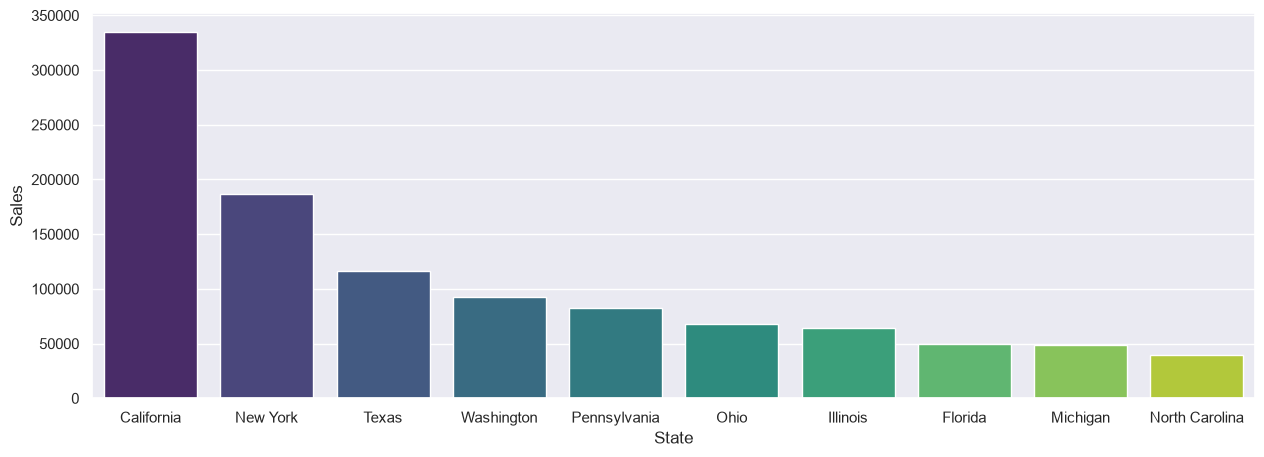

In [58]:
salesbystates = df.groupby(['State'], as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False).head(10)
sns.set(rc ={"figure.figsize":(15,5)})
sns.barplot(data = salesbystates,x = 'State',y = 'Sales',palette = 'viridis')

C:\Users\adikh\AppData\Local\Temp\ipykernel_11764\3702828046.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = profitbystates,x = 'State',y = 'Profit',palette = 'viridis')


<Axes: xlabel='State', ylabel='Profit'>

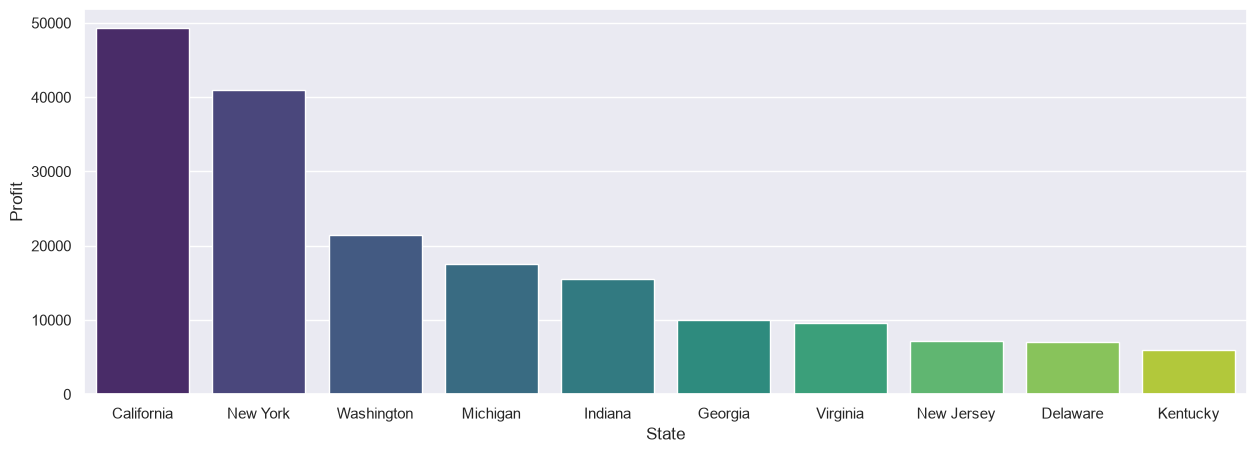

In [59]:
profitbystates = df.groupby(['State'], as_index = False)['Profit'].sum().sort_values(by = 'Profit', ascending = False).head(10)
sns.set(rc ={"figure.figsize":(15,5)})
sns.barplot(data = profitbystates,x = 'State',y = 'Profit',palette = 'viridis')

In [60]:
st = df.groupby('State')[['Sales', 'Profit']].sum()
st['margin'] = st['Profit'] / st['Sales'] * 100
print(st.sort_values('Profit', ascending=False).head(10).round(1))
print(st.sort_values('Profit').head(5).round(1))

               Sales   Profit  margin
State                                
California  335190.3  49372.2    14.7
New York    186748.1  41012.0    22.0
Washington   92975.2  21466.7    23.1
Michigan     48504.7  17480.3    36.0
Indiana      32039.2  15524.7    48.5
Georgia      37260.7   9994.4    26.8
Virginia     32721.2   9657.5    29.5
New Jersey   32086.9   7213.1    22.5
Delaware     12515.7   7029.9    56.2
Kentucky     24352.7   5968.4    24.5
                 Sales   Profit  margin
State                                  
Texas         116261.9 -14078.2   -12.1
Illinois       64224.3  -9554.7   -14.9
Ohio           68194.9  -9339.4   -13.7
Pennsylvania   82355.0  -9297.8   -11.3
Colorado       29249.1  -5825.6   -19.9


**Finding:** California (335k, 21% of all sales) and New York earn the most profit (49k and 41k), then Washington (21k). Texas, Illinois, Ohio, Pennsylvania and Colorado lose money (-6k to -14k each). Texas is a big seller (116k) that loses 14k.

### City

C:\Users\adikh\AppData\Local\Temp\ipykernel_11764\1612471183.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = topspentbycity,x = 'City',y = 'Sales',palette = 'viridis')


<Axes: xlabel='City', ylabel='Sales'>

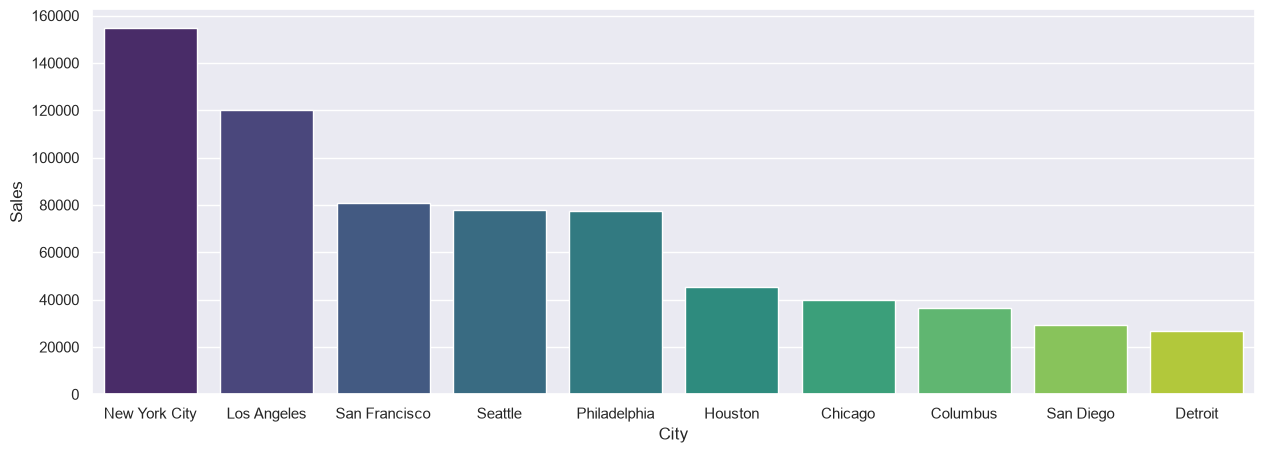

In [61]:
topspentbycity = df.groupby(['City'], as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False).head(10)

sns.set(rc ={"figure.figsize":(15,5)})
sns.barplot(data = topspentbycity,x = 'City',y = 'Sales',palette = 'viridis')

C:\Users\adikh\AppData\Local\Temp\ipykernel_11764\75121160.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = profitbycity,x = 'City',y = 'Profit',palette = 'viridis')


<Axes: xlabel='City', ylabel='Profit'>

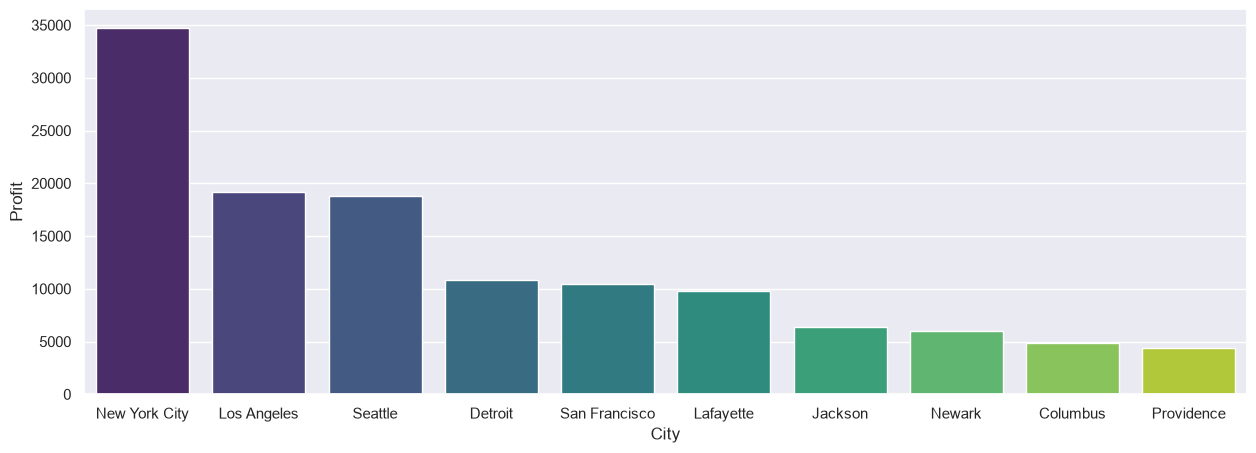

In [62]:
profitbycity = df.groupby(['City'], as_index = False)['Profit'].sum().sort_values(by = 'Profit', ascending = False).head(10)

sns.set(rc ={"figure.figsize":(15,5)})
sns.barplot(data = profitbycity,x = 'City',y = 'Profit',palette = 'viridis')

In [63]:
ct = df.groupby('City')[['Sales', 'Profit']].sum()
ct['margin'] = ct['Profit'] / ct['Sales'] * 100
print(ct.sort_values('Profit', ascending=False).head(10).round(1))

                  Sales   Profit  margin
City                                    
New York City  154919.7  34760.3    22.4
Los Angeles    120017.4  19174.9    16.0
Seattle         77924.5  18839.3    24.2
Detroit         26631.2  10803.2    40.6
San Francisco   80891.4  10475.5    13.0
Lafayette       10016.8   9772.8    97.6
Jackson         22696.3   6388.0    28.1
Newark          15319.8   6042.3    39.4
Columbus        36398.9   4818.1    13.2
Providence      10165.3   4353.6    42.8


**Finding:** New York City leads on sales (155k) and profit (35k), then Los Angeles and Seattle. Some small cities show huge margins (e.g. Lafayette 97.6% on 10k of sales). Treat these with care, they are very small samples.

### Time trend

            Sales   Profit
Month                     
2019-01   18616.0   2853.0
2019-02   19979.0   5005.0
2019-03   51716.0   3612.0
2019-04   38750.0   2978.0
2019-05   50988.0   8662.0
2019-06   40345.0   4750.0
2019-07   39262.0   4433.0
2019-08   31115.0   2062.0
2019-09   73410.0   9329.0
2019-10   42688.0  16243.0
2019-11   79412.0   4011.0
2019-12   78399.0  17885.0
2020-01   54763.0   7140.0
2020-02   52068.0   1614.0
2020-03   64229.0  14752.0
2020-04   50808.0    933.0
2020-05   66750.0   6343.0
2020-06   69243.0   8223.0
2020-07   60077.0   6953.0
2020-08   77339.0   9041.0
2020-09  119804.0  10992.0
2020-10   88897.0   9275.0
2020-11  130961.0   9690.0
2020-12  166186.0   8483.0


<Axes: xlabel='Month'>

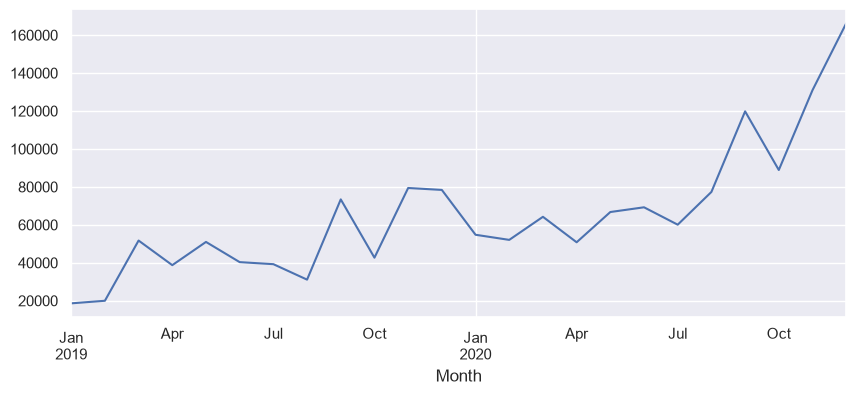

In [64]:
df['Month'] = df['Order Date'].dt.to_period('M')
monthly = df.groupby('Month')[['Sales', 'Profit']].sum()
print(monthly.round(0))
monthly['Sales'].plot(figsize=(10, 4))

          Sales   Profit  margin
Year                            
2019   564679.5  81823.4    14.5
2020  1001124.8  93438.7     9.3


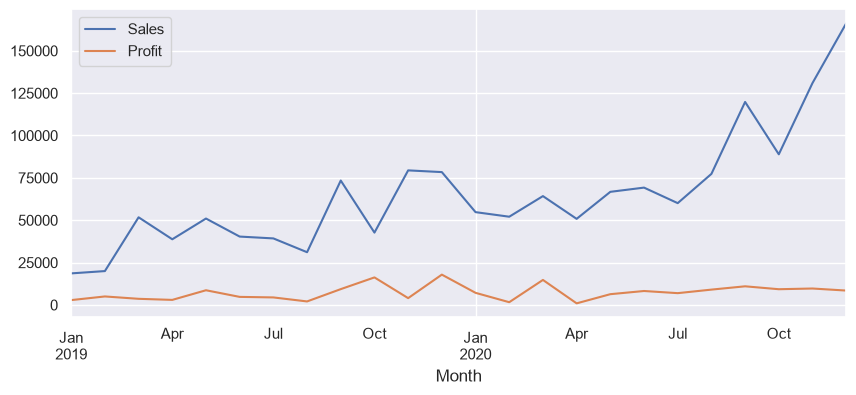

In [65]:
monthly['Margin %'] = monthly['Profit'] / monthly['Sales'] * 100
monthly[['Sales', 'Profit']].plot(figsize=(10, 4))

df['Year'] = df['Order Date'].dt.year
yr = df.groupby('Year')[['Sales', 'Profit']].sum()
yr['margin'] = yr['Profit'] / yr['Sales'] * 100
print(yr.round(1))

**Finding:** Sales rise toward the end of each year, with a huge Nov-Dec 2020 (131k and 166k). Profit stays flat while sales grow, so the lines pull apart in 2020.

In [66]:
df['Year'] = df['Order Date'].dt.year
cy = df.groupby(['Year', 'Category'])[['Sales', 'Profit']].sum()
cy['margin'] = cy['Profit'] / cy['Sales'] * 100
print(cy.round(1))

                         Sales   Profit  margin
Year Category                                  
2019 Furniture        195275.4   6988.2     3.6
     Office Supplies  174940.0  35061.2    20.0
     Technology       194464.2  39774.0    20.5
2020 Furniture        256233.3   3018.4     1.2
     Office Supplies  468767.7  39736.0     8.5
     Technology       276123.8  50684.3    18.4


**Finding:** 2019 to 2020: sales went from 565k to 1.0M (+77%), but profit only went from 82k to 93k, so margin fell from 14.5% to 9.3%.

In [67]:
o = df[df['Category'] == 'Office Supplies']
oy = o.groupby(['Sub-Category', 'Year'])[['Sales', 'Profit']].sum()
oy['margin'] = oy['Profit'] / oy['Sales'] * 100
print(oy.round(1))

                      Sales   Profit  margin
Sub-Category Year                           
Appliances   2019   25050.3   5301.3    21.2
             2020   55254.9   7865.3    14.2
Art          2019    5960.9   1414.0    23.7
             2020   44802.1   2222.0     5.0
Binders      2019   42683.3  10215.6    23.9
             2020  132295.1   7669.7     5.8
Envelopes    2019    4729.9   2066.7    43.7
             2020   11812.6   1441.8    12.2
Fasteners    2019     960.1    294.1    30.6
             2020   14245.1    304.3     2.1
Labels       2019    2827.2   1192.6    42.2
             2020   16570.2   1744.6    10.5
Paper        2019   21661.9   9071.5    41.9
             2020   77791.7  12040.8    15.5
Storage      2019   56788.7   6204.3    10.9
             2020   93552.6   7402.8     7.9
Supplies     2019   14277.6   -699.0    -4.9
             2020   22443.4   -955.3    -4.3


**Finding:** Office Supplies sales grew from 175k to 469k but its margin dropped from 20.0% to 8.5%. The biggest drops are Binders (23.9% to 5.8%), Art (23.7% to 5.0%) and Paper (41.9% to 15.5%).

In [68]:
df['Unit Price'] = df['Sales'] / df['Quantity']
b = df[df['Sub-Category'] == 'Binders']
print(b.groupby('Year').agg(units=('Quantity', 'sum'), avg_price=('Unit Price', 'mean'), profit_per_unit=('Profit', lambda p: p.sum() / b.loc[p.index, 'Quantity'].sum())).round(2))

      units  avg_price  profit_per_unit
Year                                   
2019   1603      33.19             6.37
2020   2067      84.01             3.71


**Finding:** Binders sold 29% more units in 2020 (1,603 to 2,067), and the average unit price went up (33 to 84), yet profit per unit fell (6.37 to 3.71). Price is not the reason. This dataset has no cost or discount column, so we can't say why.

### Shipping time

In [69]:
df['Ship Days'] = (df['Ship Date'] - df['Order Date']).dt.days
df.groupby('Ship Mode')['Ship Days'].agg(['min', 'mean', 'max']).round(1)

,min,mean,max
Ship Mode,,,
First Class,1,2.1,3
Same Day,0,0.1,1
Second Class,2,3.2,5
Standard Class,3,5.0,8


In [70]:
(df.groupby('Order ID')['Order Date'].nunique() > 1).sum()

np.int64(1)

In [71]:
((df['Ship Date'] - df['Order Date']).dt.days < 0).sum()

np.int64(0)

**Finding:** Shipping days match the mode: Same Day 0-1, First Class 1-3, Second Class 2-5, Standard 3-8. No order ships before it was ordered. One order ID has two different order dates, which is a small data quirk.

### Payment Mode

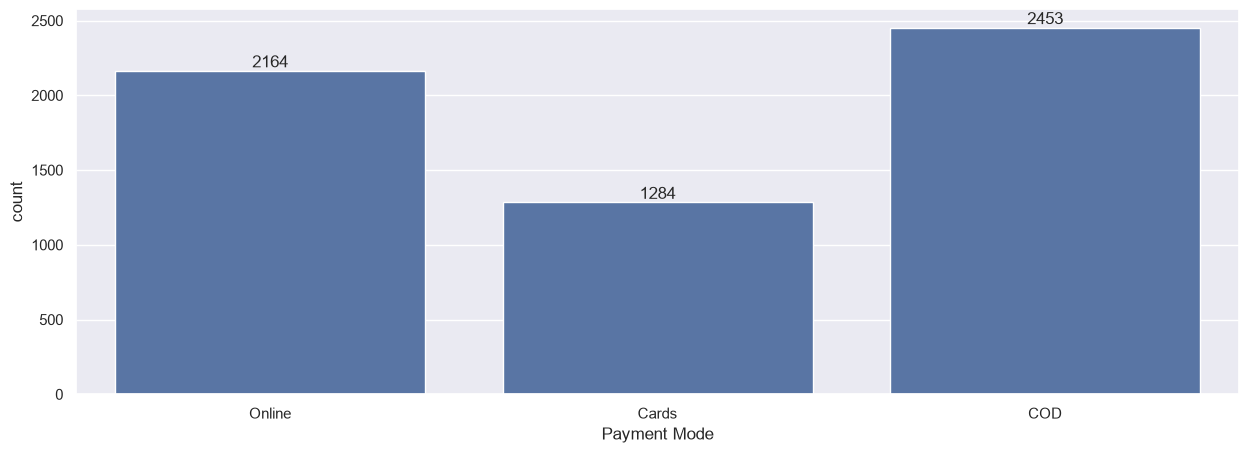

In [72]:
ax = sns.countplot(data = df,x = 'Payment Mode')

for container in ax.containers:
    ax.bar_label(container)

<Axes: xlabel='Payment Mode', ylabel='Sales'>

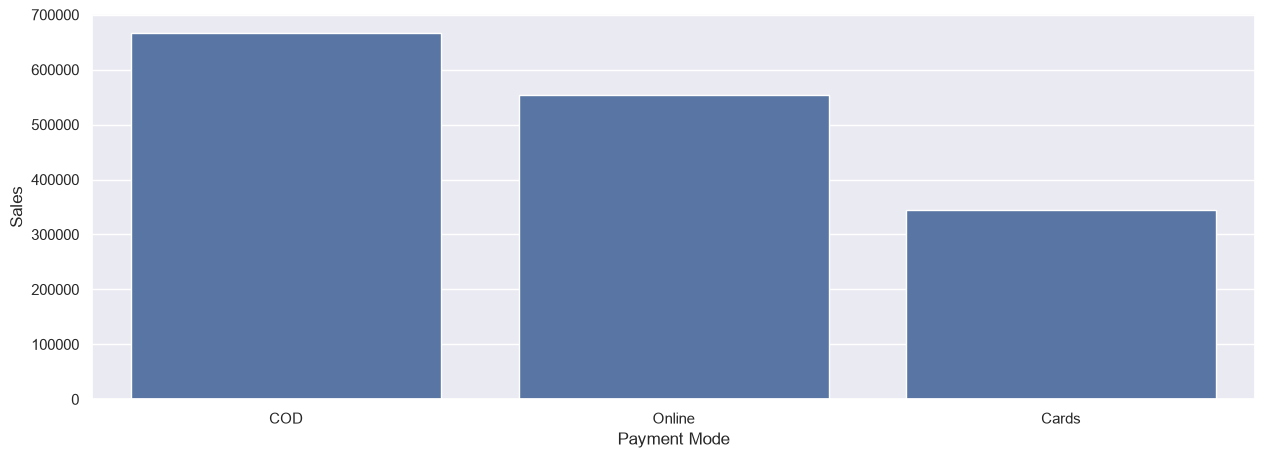

In [73]:
salesbypaymentmode = df.groupby(['Payment Mode'],as_index = False)['Sales'].sum().sort_values(by = 'Sales', ascending = False)

sns.barplot(data = salesbypaymentmode,x = 'Payment Mode',y = 'Sales')

In [74]:
pm = df.groupby('Payment Mode').agg(
    orders=('Sales', 'count'),
    sales=('Sales', 'sum'),
    avg_sale=('Sales', 'mean'),
    median_sale=('Sales', 'median'),
    profit=('Profit', 'sum'),
    return_rate=('Returns', 'mean')
)
pm['margin'] = pm['profit'] / pm['sales'] * 100
pm['return_rate'] *= 100
print(pm.round(1))

              orders     sales  avg_sale  median_sale   profit  return_rate  \
Payment Mode                                                                  
COD             2453  667417.8     272.1        132.0  82092.4          4.7   
Cards           1284  344393.1     268.2        125.3  39122.2          4.0   
Online          2164  553993.5     256.0        126.8  54047.5          5.5   

              margin  
Payment Mode          
COD             12.3  
Cards           11.4  
Online           9.8  


**Finding:** COD is the most used (2,453 rows, 667k, 43% of sales) and has the best margin (12.3%). Online has the lowest margin (9.8%) and the highest return rate (5.5%). The gaps are small.

### Outliers

<Axes: xlabel='Profit'>

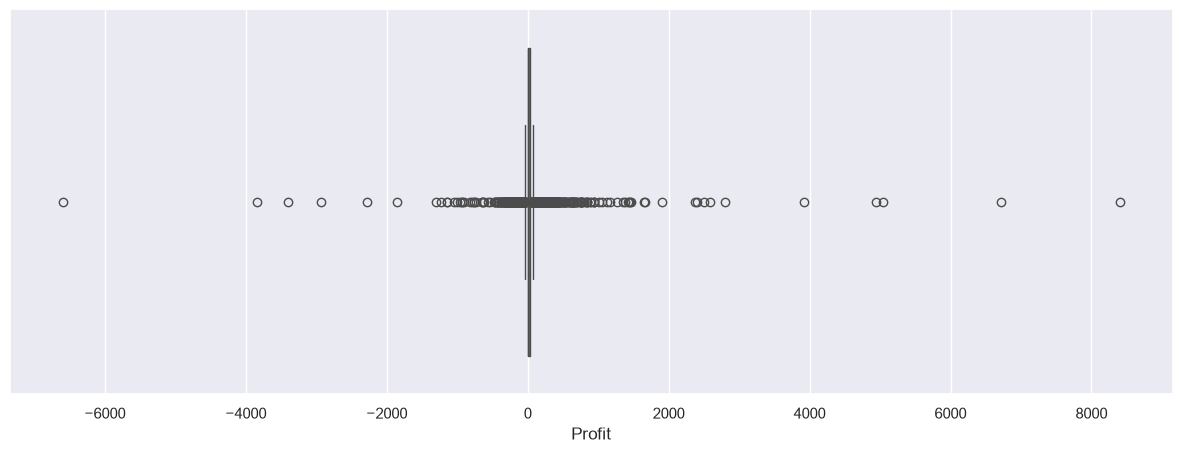

In [75]:
sns.boxplot(x=df['Profit'])

(-200.0, 200.0)

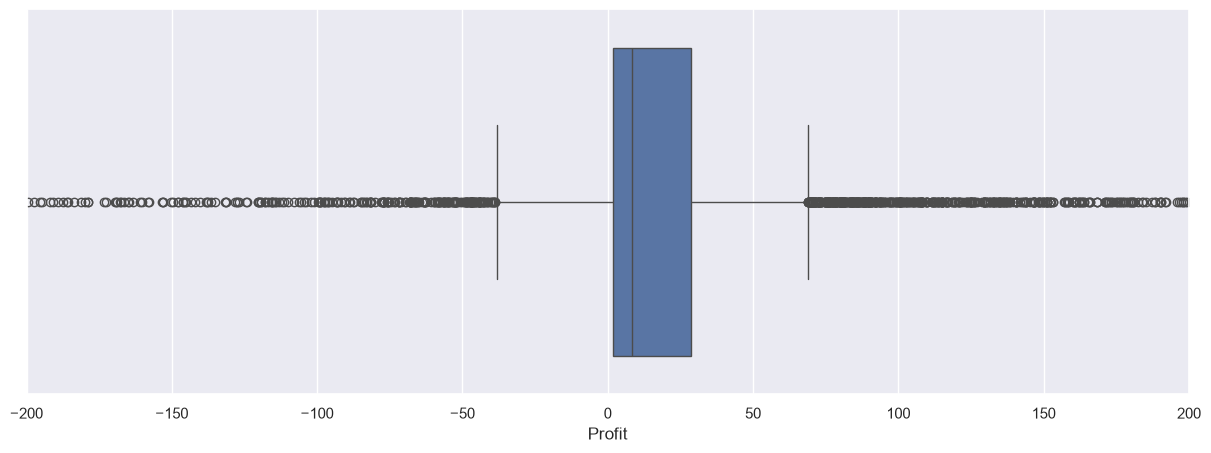

In [76]:
sns.boxplot(x=df['Profit'])
plt.xlim(-200, 200)

(-200.0, 200.0)

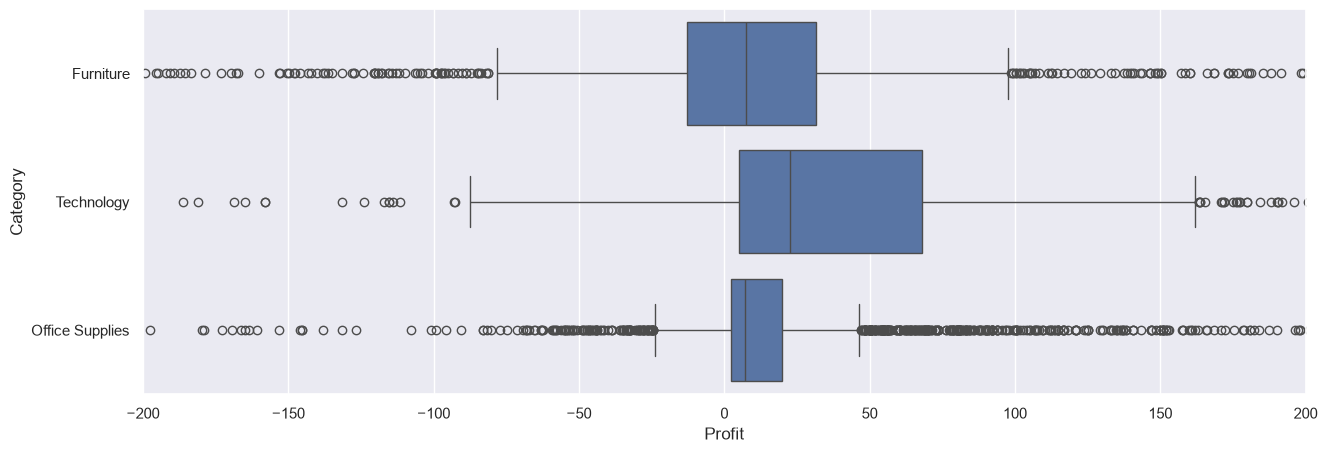

In [77]:
sns.boxplot(data=df, x='Profit', y='Category')
plt.xlim(-200, 200)

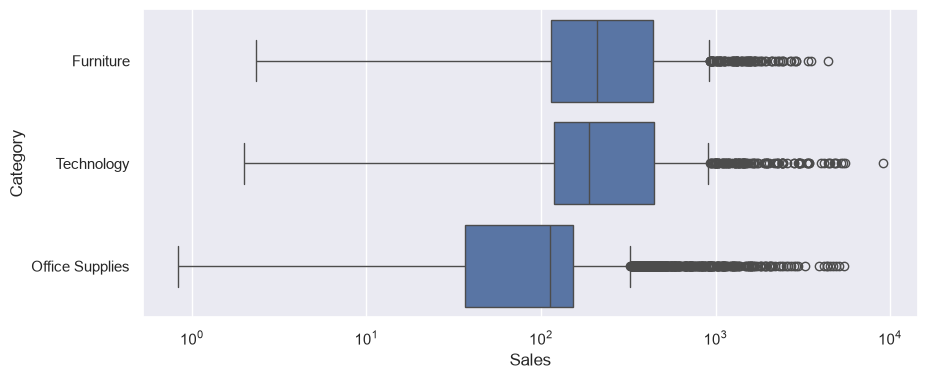

In [78]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='Sales', y='Category')
plt.xscale('log')
plt.show()

In [79]:
# 1. How many Profit outliers are there?
q1, q3 = df['Profit'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = df[(df['Profit'] < low) | (df['Profit'] > high)]

print("normal range:", round(low, 1), "to", round(high, 1))
print("outliers:", len(out), f"({len(out) / len(df) * 100:.1f}% of orders)")
print("big losses:", (df['Profit'] < low).sum(), "| big gains:", (df['Profit'] > high).sum())

normal range: -38.4 to 68.8
outliers: 1122 (19.0% of orders)
big losses: 354 | big gains: 768


In [80]:
df.nsmallest(5, 'Profit')[['Sub-Category', 'Sales', 'Profit']]

,Sub-Category,Sales,Profit
2184,Machines,4499.985,-6599.9780
5037,Machines,3009.980,-3839.9904
3193,Machines,2579.985,-3399.9800
5569,Binders,1901.990,-2929.4845
5276,Binders,1556.188,-2287.7820


In [81]:
df.nlargest(5, 'Profit')[['Sub-Category', 'Sales', 'Profit']]

,Sub-Category,Sales,Profit
1681,Copiers,499.950,8399.9760
3011,Copiers,3445.960,6719.9808
5236,Copiers,5517.970,5039.9856
2447,Binders,2892.740,4946.3700
4895,Copiers,2212.968,3919.9888


**Finding:** 1,122 rows (19%) are Profit outliers: 354 big losses and 768 big gains. They look like real orders (the biggest loss is a Machines order at -6.6k, the biggest gain a Copiers order at +8.4k), so we keep them.

#### Odd rows: profit bigger than sales

In [82]:
bad_hi = df['Profit'] > df['Sales']
bad_lo = df['Profit'] < -df['Sales']

print("profit > sales:", bad_hi.sum(), "| profit total:", round(df.loc[bad_hi, 'Profit'].sum()))
print("loss > sales:", bad_lo.sum(), "| profit total:", round(df.loc[bad_lo, 'Profit'].sum()))
df.loc[bad_hi, 'Sub-Category'].value_counts().head()

profit > sales: 14 | profit total: 29312
loss > sales: 108 | profit total: -38176


Sub-Category
Copiers        6
Storage        2
Phones         2
Accessories    2
Binders        1
Name: count, dtype: int64

In [83]:
c = df[df['Sub-Category'] == 'Copiers']
c_ok = c[c['Profit'] <= c['Sales']]
print("with all rows:", round(c['Profit'].sum() / c['Sales'].sum() * 100, 1))
print("without the odd rows:", round(c_ok['Profit'].sum() / c_ok['Sales'].sum() * 100, 1))

ok = df[df['Profit'] <= df['Sales']]
print("overall margin without them:", round(ok['Profit'].sum() / ok['Sales'].sum() * 100, 1))

with all rows: 71.6
without the odd rows: 40.5
overall margin without them: 9.4


In [84]:
df['Odd Profit'] = df['Profit'] > df['Sales']

**Finding:** 14 rows have Profit greater than Sales (29k of profit), 6 of them Copiers. This can't happen in a normal sale: profit is sales minus costs, and costs can't be negative, so profit can never be more than the sale amount. These look like data errors, so they are flagged in the `Odd Profit` column (not deleted) and can be filtered out in Power BI. They inflate Copiers (71.6% to 40.5% without them) and the overall margin (11.2% vs 9.4% without them). Separately, 108 rows lose more than their sales (-38k). That one is possible (cost higher than the sale price, e.g. heavy discounts), so these are kept and not flagged.

### Correlation

<Axes: >

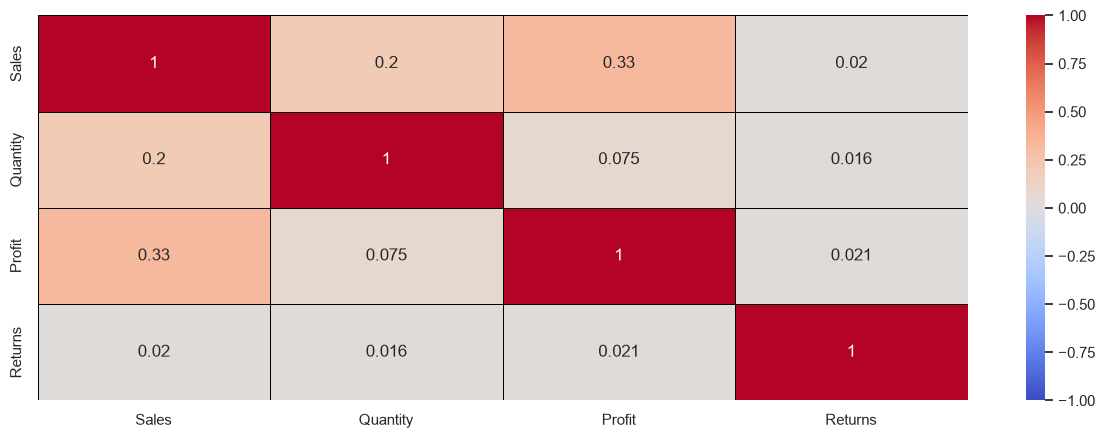

In [85]:
columns = ['Sales', 'Quantity', 'Profit', 'Returns']
sns.heatmap(df[columns].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, linecolor='black')

**Finding:** Sales and Profit are only weakly linked (0.33), Sales and Quantity even less (0.20), and Quantity and Profit almost not at all (0.07). Returns correlates only ~0.02 with all of them, so order size and profit don't predict returns. Selling more doesn't automatically mean earning more.

## Conclusion

### Who leads (one line)
By sales, **Standard Class** leads Ship Mode (58%), **Consumer** leads Segment (48%), **West** leads Region (33%), **Office Supplies** leads Category (41%), **Phones** leads Sub-Category, **California** leads State (21%), **New York City** leads City (10%) and **COD** leads Payment Mode (43%). By profit, **Technology** beats Office Supplies, **Copiers** is the top sub-category (but inflated by odd rows), and California and New York City stay on top. Weakest: **Tables** (-9.3%), **Central** region (8.0% margin) and **Texas** (-14k).

### Key findings
1. **Sales grew, profit didn't.** Sales went from about 565k (2019) to 1.0M (2020), but profit only moved from about 82k to 93k. Margin fell from 14.5% to 9.3%.
2. **Office Supplies drove the growth** (175k to 469k) while its margin dropped from 20.0% to 8.5%. Binders, Art and Paper margins collapsed in 2020.
3. **Technology is the money maker** (about 19% margin). **Furniture is weak** (about 2%). Tables lose money overall and in every region. Supplies lose too, Machines are about break-even.
4. **Loss-making states:** Texas, Illinois, Ohio, Pennsylvania, Colorado. Top profit: California, New York, Washington.
5. **Central has the lowest margin** (8.0%), driven by Furnishings, Bookcases and Binders. West has the best (13.0%).
6. **Returns:** 4.9% of rows, 3.5% of orders (104 of 3,003). West is high (9.9%) because of a few customers, mostly in California and Washington. Returns have almost no link with order size or profit. Shipping time doesn't affect returns either.
7. **Ship Mode, Segment and Payment Mode are flat**: no big differences in sales, margin or returns.
8. **Data quirks:** 14 rows have Profit greater than Sales and they inflate Copiers and the overall margin. 108 rows lose more than their sales. 19% of rows are Profit outliers (kept).
9. **Correlations are weak:** nothing in Sales, Quantity or Profit strongly predicts anything else.